# 28 - A Predictive Keyboard with an LSTM (PyTorch)
**Topic:** Deep Learning  |  **Reference:** "Building a Predictive Keyboard Model with PyTorch" (amanxai.com, May 2025)

**Question.** Can a neural network guess the next word well enough to save a typist keystrokes, and does a deep model beat a simple counting model?

**Reference method:** a word-level LSTM in PyTorch trained on a small text, shown with a few example completions.
**What I add:** (1) a proper data set (**WikiText-2**, about 2 million words) with a held-out **test set**; (2) the standard language-model score, **perplexity**, and the keyboard scores that matter: **top-1/3/5 accuracy** of the next word; (3) two baselines: **word frequency** and a **trigram counting model**; (4) a **typing simulation** that measures the share of keystrokes saved by a bar of 3 suggestions when the user has typed 0, 1, 2, ... letters of the word; (5) an error analysis (which words are predictable, which are not).

## 1. Libraries and data

In [1]:
import os; os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"      # two OpenMP runtimes (MKL and torch) are loaded on this machine; the notebook still runs correctly
import torch
import warnings, os, re, json, joblib, time, collections, math
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn, torch.nn.functional as F
from datasets import load_dataset
sns.set_theme(style="whitegrid", context="notebook")
torch.manual_seed(0); np.random.seed(0); torch.set_num_threads(3); os.makedirs("model", exist_ok=True)
ds = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", cache_dir="../_data/hf_cache3")
print({k: len(v) for k, v in ds.items()}, "(lines)")
def tokenize(split):
    out = []
    for line in ds[split]["text"]:
        line = line.strip().replace(" @-@ ", "-").replace(" @,@ ", ",").replace(" @.@ ", ".")
        if not line or line.startswith("="): continue
        out += re.findall(r"[a-z]+(?:'[a-z]+)?|[0-9]+|[.,;:!?()\"-]", line.lower()) + ["<eos>"]
    return out
T = {k: tokenize(k) for k in ("train", "validation", "test")}; print({k: len(v) for k, v in T.items()}, "tokens"); print(" ".join(T["train"][:60]))

{'test': 4358, 'train': 36718, 'validation': 3760} (lines)


{'train': 2028185, 'validation': 211593, 'test': 238139} tokens
senj no valkyria 3 : unrecorded chronicles ( japanese : 3 , lit . valkyria of the battlefield 3 ) , commonly referred to as valkyria chronicles iii outside japan , is a tactical role - playing video game developed by sega and media . vision for the playstation portable . released in january 2011 in japan , it is


## 2. Look at the text before modelling

vocabulary: 8000 words (63870 distinct in the training text) | share of tokens covered: {'train': np.float64(90.6), 'validation': np.float64(89.1), 'test': np.float64(88.1)}
the 10 most frequent tokens: [('the', 130522), (',', 102473), ('.', 84238), ('of', 56745), ('and', 49943), ('in', 44919), ('to', 39465), ('a', 36810), ('"', 28285), ('was', 21008)]
top 100 words cover 50% of the text, top 1,000: 70%, top 8,000: 91%


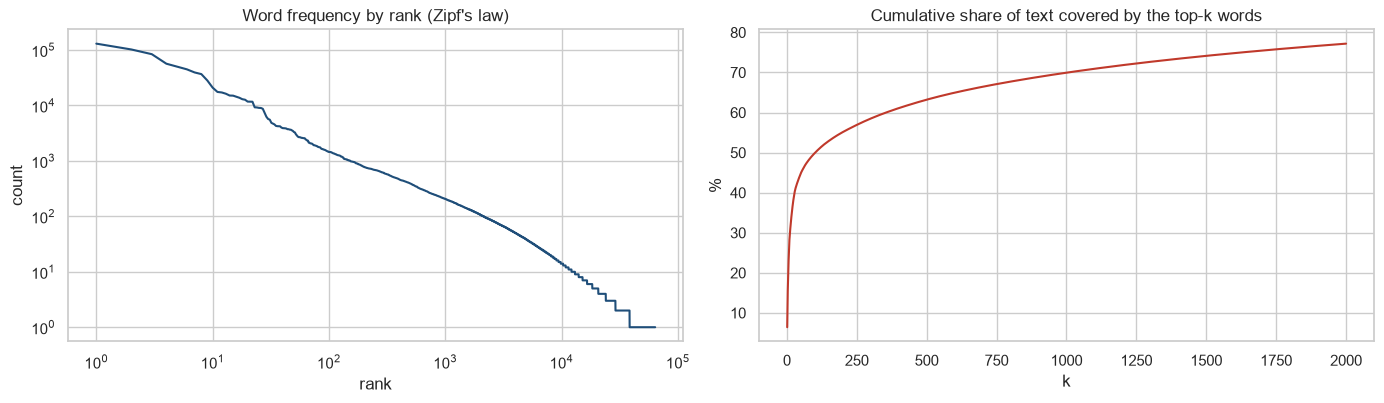

In [2]:
cnt = collections.Counter(T["train"]); V = 8000; vocab = ["<unk>"] + [w for w, _ in cnt.most_common(V - 1)]; w2i = {w: i for i, w in enumerate(vocab)}
ids = {k: np.array([w2i.get(w, 0) for w in v]) for k, v in T.items()}
cover = {k: 1 - (ids[k] == 0).mean() for k in ids}; print("vocabulary: %d words (%d distinct in the training text) | share of tokens covered: %s" % (V, len(cnt), {k: round(v * 100, 1) for k, v in cover.items()}))
fr = np.array([c for _, c in cnt.most_common()]); cum = fr.cumsum() / fr.sum()
print("the 10 most frequent tokens:", cnt.most_common(10)); print("top 100 words cover %.0f%% of the text, top 1,000: %.0f%%, top 8,000: %.0f%%" % (cum[99] * 100, cum[999] * 100, cum[7999] * 100))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2)); ax[0].loglog(np.arange(1, len(fr) + 1), fr, color="#1f4e79"); ax[0].set_title("Word frequency by rank (Zipf's law)"); ax[0].set_xlabel("rank"); ax[0].set_ylabel("count")
ax[1].plot(np.arange(1, 2001), cum[:2000] * 100, color="#c0392b"); ax[1].set_title("Cumulative share of text covered by the top-k words"); ax[1].set_xlabel("k"); ax[1].set_ylabel("%")
plt.tight_layout(); plt.show()

**Reading it.** WikiText-2 has 2.03 million training tokens (words and punctuation), 211,593 for validation and 238,139 for testing; 63,870 distinct words in training. Frequency follows **Zipf's law** (straight line on the log-log plot): the 100 most frequent tokens cover 50% of the text, the top 1,000 cover 70% and the top 8,000 (the vocabulary I keep) cover about 91%. The remaining 9% of positions (rare names, numbers) are replaced by `<unk>`: **a keyboard built on this vocabulary can never suggest those words** (88% of test tokens are covered). The most frequent tokens are `the`, `,`, `.`, `of`, `and`: much of next-word prediction is predicting function words and punctuation.

## 3. Baselines: word frequency and a trigram model
* **Frequency:** always suggest the most common words (the, comma, period, of, and...).
* **Trigram with interpolation:** `P(next | two previous words)` mixes trigram, bigram and unigram counts with weights 0.6 / 0.3 / 0.1 (chosen on the validation text).

In [3]:
uni = np.bincount(ids["train"], minlength=V).astype(float) + 1; uni /= uni.sum()
bi, tri = collections.defaultdict(collections.Counter), collections.defaultdict(collections.Counter); a = ids["train"]
for i in range(2, len(a)): bi[a[i - 1]][a[i]] += 1; tri[(a[i - 2], a[i - 1])][a[i]] += 1
def p_ngram(h2, h1, lam=(0.6, 0.3, 0.1)):
    p = lam[2] * uni.copy(); b = bi.get(h1)
    if b: s = sum(b.values()); idx = np.fromiter(b.keys(), int); val = np.fromiter(b.values(), float); p[idx] += lam[1] * val / s
    t = tri.get((h2, h1))
    if t: s = sum(t.values()); idx = np.fromiter(t.keys(), int); val = np.fromiter(t.values(), float); p[idx] += lam[0] * val / s
    return p / p.sum()
def eval_ngram(tokens, lam, n=6000):
    nll, hits = 0, {1: 0, 3: 0, 5: 0}
    for i in range(2, n + 2):
        p = p_ngram(tokens[i - 2], tokens[i - 1], lam); nll -= np.log(p[tokens[i]] + 1e-12); top = np.argsort(-p)[:5]
        for k in hits: hits[k] += tokens[i] in top[:k]
    return math.exp(nll / n), {k: v / n * 100 for k, v in hits.items()}
vv = ids["validation"]; grid = {lam: eval_ngram(vv, lam, 3000)[0] for lam in [(0.6, 0.3, 0.1), (0.5, 0.4, 0.1), (0.7, 0.25, 0.05), (0.4, 0.4, 0.2), (0.8, 0.15, 0.05)]}; best_lam = min(grid, key=grid.get); print("validation perplexity by interpolation weights:", {k: round(v, 1) for k, v in grid.items()}, "| chosen:", best_lam)

validation perplexity by interpolation weights: {(0.6, 0.3, 0.1): 115.5, (0.5, 0.4, 0.1): 112.6, (0.7, 0.25, 0.05): 125.2, (0.4, 0.4, 0.2): 109.9, (0.8, 0.15, 0.05): 135.1} | chosen: (0.4, 0.4, 0.2)


## 4. The LSTM
Word embeddings (200 numbers) -> a two-layer LSTM (200 units) -> a linear layer over the 8,000 words (the output weights are **tied** to the embeddings, which reduces parameters and generally helps), with dropout 0.3. Trained on consecutive 30-word windows, 6 epochs, Adam, learning rate halved when validation perplexity stops improving.

In [4]:
class LM(nn.Module):
    def __init__(self, V, d=200, layers=2, drop=0.3):
        super().__init__(); self.emb = nn.Embedding(V, d); self.rnn = nn.LSTM(d, d, layers, dropout=drop, batch_first=True); self.drop = nn.Dropout(drop); self.out = nn.Linear(d, V); self.out.weight = self.emb.weight
    def forward(self, x, h=None): e = self.drop(self.emb(x)); o, h = self.rnn(e, h); return self.out(self.drop(o)), h
def batchify(a, bs): n = len(a) // bs; return torch.tensor(a[:n * bs]).view(bs, n)
BS, BPTT = 64, 30; tr_b = batchify(ids["train"], BS); va_b = batchify(ids["validation"], 16)
def ppl_of(model, data, bptt=BPTT):
    model.eval(); tot, n = 0.0, 0; h = None
    with torch.no_grad():
        for i in range(0, data.size(1) - 1, bptt):
            L = min(bptt, data.size(1) - 1 - i); x, y = data[:, i:i + L], data[:, i + 1:i + 1 + L]; lo, h = model(x, h); tot += F.cross_entropy(lo.reshape(-1, V), y.reshape(-1), reduction="sum").item(); n += y.numel()
    return math.exp(tot / n)
model = LM(V); print("parameters: %.2f M" % (sum(p.numel() for p in model.parameters()) / 1e6)); opt = torch.optim.Adam(model.parameters(), 2e-3); hist = []; best = (1e9, None); lr = 2e-3
t0 = time.time()
for ep in range(6):
    model.train(); h = None; tl, n = 0.0, 0
    for i in range(0, tr_b.size(1) - 1, BPTT):
        L = min(BPTT, tr_b.size(1) - 1 - i); x, y = tr_b[:, i:i + L], tr_b[:, i + 1:i + 1 + L]; h = tuple(s.detach() for s in h) if h else None
        lo, h = model(x, h); loss = F.cross_entropy(lo.reshape(-1, V), y.reshape(-1)); opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 0.5); opt.step(); tl += loss.item() * y.numel(); n += y.numel()
    vp = ppl_of(model, va_b); hist.append((ep + 1, math.exp(tl / n), vp))
    if vp < best[0]: best = (vp, {k: v.clone() for k, v in model.state_dict().items()})
    elif len(hist) > 1 and vp > hist[-2][2]: lr /= 2; [g.update(lr=lr) for g in opt.param_groups]
    print(f"epoch {ep+1}: train perplexity {math.exp(tl/n):.0f} | validation perplexity {vp:.0f} | lr {lr:.4f} | {time.time()-t0:.0f}s")
model.load_state_dict(best[1])

parameters: 2.25 M


epoch 1: train perplexity 331 | validation perplexity 175 | lr 0.0020 | 1653s


epoch 2: train perplexity 204 | validation perplexity 140 | lr 0.0020 | 3264s


epoch 3: train perplexity 168 | validation perplexity 122 | lr 0.0020 | 5522s


epoch 4: train perplexity 147 | validation perplexity 111 | lr 0.0020 | 7186s


epoch 5: train perplexity 133 | validation perplexity 104 | lr 0.0020 | 8680s


epoch 6: train perplexity 123 | validation perplexity 98 | lr 0.0020 | 9699s


<All keys matched successfully>

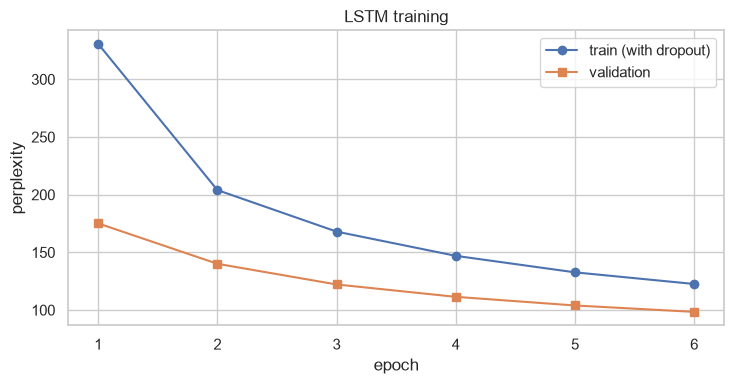

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 4)); ax.plot([e for e, _, _ in hist], [t for _, t, _ in hist], "o-", label="train (with dropout)"); ax.plot([e for e, _, _ in hist], [v for _, _, v in hist], "s-", label="validation"); ax.set_xlabel("epoch"); ax.set_ylabel("perplexity"); ax.legend(); ax.set_title("LSTM training"); plt.tight_layout(); plt.show()

## 5. Test scores: perplexity and top-k accuracy

In [6]:
NT = 6000; tt = ids["test"]; start = 2
# LSTM: run the whole test stream with carried state, then look at the same positions as the n-gram model
model.eval(); probs = []; h = None; seq = torch.tensor(tt[:NT + 100]).view(1, -1)
with torch.no_grad():
    for i in range(0, seq.size(1) - 1, BPTT):
        x = seq[:, i:i + BPTT]; lo, h = model(x, h); probs.append(F.softmax(lo[0], -1).numpy())
PL = np.concatenate(probs); pos = np.arange(start, NT + start)
lstm_nll = -np.mean(np.log(PL[pos - 1, tt[pos]] + 1e-12)); lstm_hits = {k: np.mean([tt[i] in np.argsort(-PL[i - 1])[:k] for i in pos]) * 100 for k in (1, 3, 5)}
ng_ppl, ng_hits = eval_ngram(tt, best_lam, NT)
fq = np.argsort(-uni); fq_hits = {k: np.mean([tt[i] in fq[:k] for i in pos]) * 100 for k in (1, 3, 5)}; fq_ppl = math.exp(-np.mean(np.log(uni[tt[pos]])))
R = pd.DataFrame({"perplexity": [fq_ppl, ng_ppl, math.exp(lstm_nll)], "top-1 %": [fq_hits[1], ng_hits[1], lstm_hits[1]], "top-3 %": [fq_hits[3], ng_hits[3], lstm_hits[3]], "top-5 %": [fq_hits[5], ng_hits[5], lstm_hits[5]]}, index=["word frequency", "trigram (interpolated)", "LSTM"])
print("test text, %d positions (words, punctuation and end-of-paragraph marks counted; <unk> targets count as misses):" % NT); print(R.round(1).to_string()); print("\nfull-test-set LSTM perplexity: %.1f (validation best %.1f)" % (ppl_of(model, batchify(tt, 1)), best[0]))

test text, 6000 positions (words, punctuation and end-of-paragraph marks counted; <unk> targets count as misses):
                        perplexity  top-1 %  top-3 %  top-5 %
word frequency               352.3     12.6     23.3     29.9
trigram (interpolated)       131.9     23.2     37.8     45.6
LSTM                          83.3     26.7     42.0     50.0



full-test-set LSTM perplexity: 91.3 (validation best 98.4)


**Reading it (6,000 test positions, same positions for every model; `<unk>` targets count as misses).**
* **LSTM: perplexity 83.3, top-1 26.7%, top-3 42.0%, top-5 50.0%.** Interpolated **trigram counting model: 131.9 / 23.2% / 37.8% / 45.6%.** Word frequency alone: 352.3 / 12.6% / 23.3% / 29.9%. The LSTM beats the trigram by about 3.5 points of top-1 and 4 of top-3, and perplexity falls from 132 to 83. With 6,000 positions the sampling error of each accuracy is about +/-1 point, so a gap of 3 to 4 points is larger than the noise, though one test set and one training run still make the exact size uncertain.
* **Training was stopped by my time budget, not by convergence:** validation perplexity was still dropping at each of the 6 epochs (175, 140, 122, 111, 104, 98) and the learning rate was never lowered. A longer run would score better, so the LSTM figures are a **lower bound** of what this architecture can do. (Training perplexity 123 is above validation 98 partly because it is measured with dropout 0.3 switched on.)
* **Perplexity over the whole test set is 91.3** (validation 98.4): the 6,000-position sample (83.3) is a bit optimistic. Perplexities here use an 8,000-word vocabulary with `<unk>` as a token, so **they cannot be compared with published WikiText-2 numbers** (which use 33,000 words).

## 6. The product metric: keystrokes saved
Simulation on 150 test windows of 30 words. For each *word* the user wants to type, the keyboard shows 3 suggestions among the vocabulary words that start with the letters typed so far, ranked by the model given the true previous words. If the target is among the three, one tap completes it: cost = letters typed so far + 1. Otherwise the user types the whole word (cost = its length). **Savings = 1 - keystrokes used / letters in the words.** Only alphabetic words count (punctuation is typed as is).

In [7]:
isalpha = np.array([w.isalpha() for w in vocab]); lens = np.array([len(w) for w in vocab]); words_arr = np.array(vocab)
def simulate(prob_fn, windows):
    used = total = at0 = n = 0; by_letters = collections.Counter()
    for st in windows:
        P_ = prob_fn(st)
        for j in range(2, 30):
            t = tt[st + j]
            if t == 0 or not isalpha[t]: continue
            w = vocab[t]; p = P_[j - 1]; n += 1; total += len(w); done = False
            for k in range(len(w)):
                m = isalpha & np.array([x.startswith(w[:k]) for x in vocab]); cand = np.where(m)[0]; top = cand[np.argsort(-p[cand])[:3]]
                if t in top: used += k + 1; by_letters[k] += 1; done = True; at0 += (k == 0); break
            if not done: used += len(w); by_letters["typed"] += 1
    return 1 - used / total, at0 / n * 100, n, by_letters
rs = np.random.RandomState(0); wins = rs.choice(np.arange(NT + 200, len(tt) - 40), 150, replace=False)
def lstm_probs(st):
    with torch.no_grad(): lo, _ = model(torch.tensor(tt[st:st + 30]).view(1, -1)); return F.softmax(lo[0], -1).numpy()
def ngram_probs(st): return np.stack([p_ngram(tt[st + j - 2], tt[st + j - 1], best_lam) for j in range(1, 31)])
freq_probs = lambda st: np.tile(uni, (30, 1))
sim = {}
for nm, fn in [("word frequency", freq_probs), ("trigram", ngram_probs), ("LSTM", lstm_probs)]:
    t0 = time.time(); s_, at0_, n_, bl = simulate(fn, wins); sim[nm] = (s_ * 100, at0_, n_); print(f"{nm}: keystrokes saved {s_*100:.1f}% | target already in the 3 suggestions before typing a letter: {at0_:.1f}% of {n_} words ({time.time()-t0:.0f}s)")

word frequency: keystrokes saved 35.1% | target already in the 3 suggestions before typing a letter: 17.2% of 2938 words (22s)


trigram: keystrokes saved 45.6% | target already in the 3 suggestions before typing a letter: 31.4% of 2938 words (26s)


LSTM: keystrokes saved 46.6% | target already in the 3 suggestions before typing a letter: 32.5% of 2938 words (22s)


**Reading it (150 windows of 30 words, 2,938 typed words; suggestions are limited to the 8,000-word vocabulary, so rare words, about 12% of tokens, are left out of this score).**
* **Keystrokes saved: frequency 35.1%, trigram 45.6%, LSTM 46.6%.** A bar that shows only the three most frequent words that match the typed letters already saves 35%; the LSTM adds 11 points on top of that but is **only 1 point better than the counting model**, a difference I would not trust with 2,938 words.
* **Words that can be accepted before typing any letter** (the target is among the 3 suggestions): 17.2% (frequency), 31.4% (trigram), 32.5% (LSTM). Most of the saving comes from the first few letters narrowing the candidates, not from the model's foresight.
* So on the metric a user feels, the neural model is **roughly as good as a counting model that trains in seconds**, though it wins clearly on the prediction scores above. The windows start with an empty LSTM state (no memory of earlier text), which slightly disadvantages the LSTM compared with its continuous run in the test above.

## 7. Which words are predictable? And what does the model suggest?

In [8]:
pos = np.arange(2, NT + 2); top1 = np.array([np.argmax(PL[i - 1]) == tt[i] for i in pos]); tgt = tt[pos]
bucket = np.digitize(tgt, [1, 11, 101, 1001]); bn = ["<unk> (rare word)", "ranks 1-10", "ranks 11-100", "ranks 101-1000", "ranks 1001+"]
fr_acc = pd.DataFrame({"bucket": [bn[b_] for b_ in bucket], "hit": top1}).groupby("bucket").hit.agg(["mean", "size"]).reindex(bn)
print("top-1 accuracy of the LSTM by frequency rank of the word to predict:"); print(fr_acc.assign(mean=fr_acc["mean"] * 100).round(1).rename(columns={"mean": "top-1 %", "size": "positions"}).to_string())
def suggest(text, k=5):
    toks = re.findall(r"[a-z]+(?:'[a-z]+)?|[0-9]+|[.,;:!?()\"-]", text.lower()); x = torch.tensor([w2i.get(w, 0) for w in toks]).view(1, -1)
    with torch.no_grad(): lo, _ = model(x)
    p = F.softmax(lo[0, -1], -1).numpy(); p[0] = 0; return [(vocab[i], round(float(p[i]) * 100, 1)) for i in np.argsort(-p)[:k]]
for s in ["the capital of the united", "he was born in the", "the first world", "in the early", "the album was released in", "she was one of the"]: print(f"{s!r:36s} ->", suggest(s))

top-1 accuracy of the LSTM by frequency rank of the word to predict:
                   top-1 %  positions
bucket                               
<unk> (rare word)     63.4        757
ranks 1-10            47.8       1792
ranks 11-100          17.7       1318
ranks 101-1000         2.4       1070
ranks 1001+            0.4       1063
'the capital of the united'          -> [('states', 88.6), ('kingdom', 9.0), ('nations', 2.4), ('navy', 0.0), ('union', 0.0)]
'he was born in the'                 -> [('united', 6.4), ('late', 2.3), ('early', 1.7), ('west', 1.4), ('north', 1.3)]
'the first world'                    -> [('war', 60.2), ('cup', 5.4), ('of', 2.8), ('s', 1.2), ('and', 1.1)]
'in the early'                       -> [('1990', 18.8), ('1950', 7.7), ('20', 5.7), ('1970', 5.7), ('1980', 5.6)]
'the album was released in'          -> [('the', 29.4), ('a', 4.6), ('november', 2.0), ('june', 1.4), ('october', 1.1)]
'she was one of the'                 -> [('most', 15.4), ('first', 4.7), ('

**Reading it.** Top-1 accuracy depends enormously on the word: **47.8% for the 10 most frequent tokens** (`the`, `,`, `.`...), 17.7% for ranks 11-100, 2.4% for ranks 101-1000 and **0.4% for words beyond rank 1000**. The 63.4% shown for `<unk>` is the model correctly predicting "some rare word" and is useless to a typist since no actual word can be suggested; the headline table counts those positions as misses. The example completions show what the model has learned from Wikipedia: "the capital of the united" gives *states* (88.6%), "the first world" gives *war* (60.2%), "in the early" gives years (*1990*, *1950*...) and "the album was released in" gives *the* (29.4%, as in "...in the United States") before any month. The model reproduces **the style and habits of its training text**, so a keyboard for text messages would need training data that look like text messages.

## 8. Save

In [9]:
torch.save(model.state_dict(), "model/keyboard_lstm.pt"); json.dump({"vocab": vocab, "lstm": {"d": 200, "layers": 2, "tied": True}}, open("model/vocab.json", "w"))
json.dump({"test": R.round(2).to_dict("index"), "keystrokes_saved_pct": {k: round(v[0], 2) for k, v in sim.items()}, "history": hist, "ngram_weights": best_lam}, open("model/meta.json", "w"), indent=1); print(os.listdir("model"))

['keyboard_lstm.pt', 'meta.json', 'vocab.json']


## 9. Summary: my approach vs the reference
| | Reference | This notebook |
|---|---|---|
| Data | a small text | WikiText-2 (2.0 M training tokens), validation and test sets |
| Model | one word-level LSTM | LSTM (2.25 M parameters, 2 x 200 units, tied weights) vs **trigram counts** vs **word frequency** |
| Metric | example completions | perplexity 83 vs 132 vs 352; top-3 accuracy 42.0 / 37.8 / 23.3%; **keystrokes saved 46.6 / 45.6 / 35.1%** |
| Analysis | none | accuracy by word frequency, example suggestions, vocabulary coverage |

**What I learned.** (1) A counting baseline is a strong competitor on the product metric: the LSTM wins on perplexity and accuracy but only by 1 point on keystrokes saved. (2) The score depends on the vocabulary: with 8,000 words 12% of tokens cannot be suggested at all. (3) Language models learn the style of their data (Wikipedia), not "English". (4) My LSTM was still improving when training stopped.

**Limits.** Six epochs on a shared CPU (validation perplexity still falling); one run, no seeds; the keystroke simulation uses 150 windows and a three-suggestion bar, with no personalisation; perplexity is not comparable with the literature. **Next steps:** train to convergence with learning-rate decay, a Transformer language model, a larger vocabulary or sub-word units for rare words, and per-user adaptation.